# ESS11 — Impact de la confiance sur le bonheur

**Source des données** : [European Social Survey (ESS), Round 11](https://ess.sikt.no/en/series/50ebb530-c72e-4002-a7bf-5581e3fdfe21) — sous-ensemble `ESS_start.csv` préparé à l'étape 1.

**Étape 3 — Index de bonheur et régressions**

On construit un **index de bonheur** à partir des trois mesures disponibles dans `ESS_start.csv` :
- `happy` : bonheur (0-10) ;
- `stflife` : satisfaction dans la vie (0-10) ;
- `health` : santé subjective (1-5, **inversée** pour que haut = bonne santé).

Les trois items sont standardisés (z-scores) puis moyennés, après vérification de la cohérence interne (alpha de Cronbach). On estime ensuite l'effet de la confiance par **régression** (MCO pondérés par `anweight`) :
- **M1** : index de bonheur ~ confiance institutionnelle + interpersonnelle ;
- **M2** : M1 + contrôles socio-démographiques et effets fixes pays.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

df = pd.read_csv("data/ESS_start.csv")
print(f"{df.shape[0]:,} répondants x {df.shape[1]} colonnes "
      f"(scores de confiance présents : {df['trust_inst'].notna().sum():,})")

46,162 répondants x 52 colonnes (scores de confiance présents : 40,602)


## 1. Construction de l'index de bonheur

In [2]:
def cronbach_alpha(items):
    k = items.shape[1]
    var_items = items.var(axis=0, ddof=1).sum()
    var_total = items.sum(axis=1).var(ddof=1)
    return k / (k - 1) * (1 - var_items / var_total)

# Inversion de health (1 = très bonne -> 5 = très bonne)
df["health_rev"] = 6 - df["health"]

bonheur_items = ["happy", "stflife", "health_rev"]
complet = df[bonheur_items].dropna()

print("Corrélations entre items :")
print(complet.corr().round(3))
print(f"\nAlpha de Cronbach : {cronbach_alpha(complet):.3f}")

# Index : moyenne des z-scores (répondants avec les 3 items)
z = (complet - complet.mean()) / complet.std(ddof=1)
df["bonheur_index"] = z.mean(axis=1)

df.to_csv("data/ESS_start.csv", index=False)
print(f"\nESS_start.csv mis à jour ({df.shape[1]} colonnes, "
      f"index disponible pour {df['bonheur_index'].notna().sum():,} répondants)")
df["bonheur_index"].describe().round(3)

Corrélations entre items :
            happy  stflife  health_rev
happy       1.000    0.687       0.311
stflife     0.687    1.000       0.283
health_rev  0.311    0.283       1.000

Alpha de Cronbach : 0.696

ESS_start.csv mis à jour (54 colonnes, index disponible pour 45,660 répondants)


count    45660.000
mean         0.000
std          0.786
min         -3.526
25%         -0.398
50%          0.129
75%          0.549
max          1.359
Name: bonheur_index, dtype: float64

## 2. Régressions : bonheur ~ confiance

In [3]:
reg_vars = ["bonheur_index", "trust_inst", "trust_interp", "anweight",
            "gndr", "agea", "eisced", "hinctnta", "cntry"]
d = df[reg_vars].dropna().copy()
d["femme"] = (d["gndr"] == 2).astype(int)
print(f"Échantillon de régression : {len(d):,} répondants")

# M1 : confiance seule
m1 = smf.wls("bonheur_index ~ trust_inst + trust_interp",
             data=d, weights=d["anweight"]).fit()

# M2 : + contrôles socio-démo et effets fixes pays
m2 = smf.wls("bonheur_index ~ trust_inst + trust_interp + femme + agea "
             "+ eisced + hinctnta + C(cntry)",
             data=d, weights=d["anweight"]).fit()

print(f"\nM1 : R² = {m1.rsquared:.3f} | M2 : R² = {m2.rsquared:.3f}")
print(m1.summary2().tables[1].round(3))

Échantillon de régression : 31,869 répondants

M1 : R² = 0.110 | M2 : R² = 0.193
              Coef.  Std.Err.       t  P>|t|  [0.025  0.975]
Intercept     0.017     0.004   4.274    0.0   0.009   0.025
trust_inst    0.123     0.005  23.898    0.0   0.113   0.133
trust_interp  0.210     0.006  36.871    0.0   0.199   0.221


## 3. Comparaison des modèles et visualisation

                 M1                M2 (+ contrôles, EF pays)                
              Coef. Std.Err. P>|t|                     Coef. Std.Err.  P>|t|
Intercept     0.017    0.004   0.0                    -0.015    0.033  0.641
agea            NaN      NaN   NaN                    -0.004    0.000  0.000
eisced          NaN      NaN   NaN                     0.014    0.002  0.000
femme           NaN      NaN   NaN                     0.011    0.008  0.167
hinctnta        NaN      NaN   NaN                     0.059    0.002  0.000
trust_inst    0.123    0.005   0.0                     0.107    0.005  0.000
trust_interp  0.210    0.006   0.0                     0.167    0.006  0.000


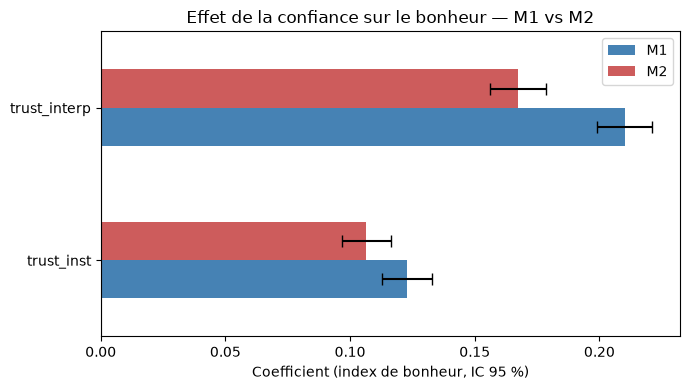

In [4]:
# Comparaison M1 / M2 (hors effets fixes pays)
def extract(model, name):
    t = model.summary2().tables[1]
    t = t[~t.index.str.startswith("C(cntry)")]
    out = t[["Coef.", "Std.Err.", "P>|t|"]].round(3)
    out.columns = pd.MultiIndex.from_product([[name], out.columns])
    return out

comp = extract(m1, "M1").join(extract(m2, "M2 (+ contrôles, EF pays)"), how="outer")
print(comp.to_string())

# Graphique des coefficients de confiance
coefs = pd.DataFrame({
    "M1": m1.params[["trust_inst", "trust_interp"]],
    "M2": m2.params[["trust_inst", "trust_interp"]],
})
errs = pd.DataFrame({
    "M1": 1.96 * m1.bse[["trust_inst", "trust_interp"]],
    "M2": 1.96 * m2.bse[["trust_inst", "trust_interp"]],
})
fig, ax = plt.subplots(figsize=(7, 4))
coefs.plot.barh(xerr=errs, ax=ax, color=["steelblue", "indianred"], capsize=4)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("Coefficient (index de bonheur, IC 95 %)")
ax.set_title("Effet de la confiance sur le bonheur — M1 vs M2")
plt.tight_layout()
plt.savefig("image/bonheur_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()